In [ ]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, LSTM, Dropout, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
# check sample data
dga.head(10)

,label,origin,domain
0,dga,gozi,mortiscontrastatim.com
1,dga,corebot,cvyh1po636avyrsxebwbkn7.ddns.net
2,legit,alexa,plasticbags.sa.com
3,legit,alexa,mzltrack.com
4,legit,alexa,miss-slim.ru
5,dga,ranbyus,txumyqrubwutbb.cc
6,legit,alexa,myhostingpack.com
7,dga,symmi,ixekrihagimau.ddns.net
8,dga,emotet,rjyuosmhfnaedlyg.eu
9,dga,dircrypt,djqrmauttlloabj.com


In [ ]:
# convert all values into lowercase
dga = dga.apply(lambda x: x.astype(str).str.lower())
# add a column named 'domain_list' -  in order to seperate it into detailed domain information later
dga['domain_list'] = dga['domain'].apply(lambda x: x.split('.'))
dga.head()

,label,origin,domain,domain_list
0,dga,gozi,mortiscontrastatim.com,"[mortiscontrastatim, com]"
1,dga,corebot,cvyh1po636avyrsxebwbkn7.ddns.net,"[cvyh1po636avyrsxebwbkn7, ddns, net]"
2,legit,alexa,plasticbags.sa.com,"[plasticbags, sa, com]"
3,legit,alexa,mzltrack.com,"[mzltrack, com]"
4,legit,alexa,miss-slim.ru,"[miss-slim, ru]"


In [ ]:
# analyse domain_list

# first, deal with instances with only two elements(pri+tld) in 'domain_list'
dga2 = dga[dga['domain_list'].apply(lambda x: True if len(x)==2 else False)]
# split them into two columns as primary1 and tld1
# add two empty columns:primary2 and tld2
dga2['primary1'] = dga['domain_list'].apply(lambda x: x[0])
dga2['primary2'] = ''
dga2['tld1'] = dga['domain_list'].apply(lambda x: x[1])
dga2['tld2'] = ''
dga2.head()

C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\215562596.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga2['primary1'] = dga['domain_list'].apply(lambda x: x[0])
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\215562596.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga2['primary2'] = ''
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\215562596.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value 

,label,origin,domain,domain_list,primary1,primary2,tld1,tld2
0,dga,gozi,mortiscontrastatim.com,"[mortiscontrastatim, com]",mortiscontrastatim,,com,
3,legit,alexa,mzltrack.com,"[mzltrack, com]",mzltrack,,com,
4,legit,alexa,miss-slim.ru,"[miss-slim, ru]",miss-slim,,ru,
5,dga,ranbyus,txumyqrubwutbb.cc,"[txumyqrubwutbb, cc]",txumyqrubwutbb,,cc,
6,legit,alexa,myhostingpack.com,"[myhostingpack, com]",myhostingpack,,com,


In [ ]:
# read common TLD information from TLDlist.txt(downloaded from ICANN)
# skip comments, use '/n' as delimiter, convert into lowercase
from numpy import loadtxt
#tld = loadtxt("TLDlist.txt", dtype=str, comments="#", delimiter="\n", unpack=False)
tld = pd.read_csv("TLDlist.txt", comment="#", header=None)[0].dropna().tolist()
tld = [x.lower() for x in tld]

In [ ]:
# deal with instances with three elements in 'domain_list'

dga3 = dga[dga['domain_list'].apply(lambda x: True if len(x)==3 else False)]

# for instances with three domain elements(pri1+tld1+tld2, both tld1 and tld2 belong to common TLD)
# split them into three columns as primary1, tld1, tld2
# add one empty column primary2
dga3_1 = dga3[dga3['domain_list'].apply(lambda x: True if x[-2] in tld and x[-1] in tld else False)]
dga3_1['primary1'] = dga3['domain_list'].apply(lambda x: x[0])
dga3_1['primary2'] = ''
dga3_1['tld1'] = dga3['domain_list'].apply(lambda x: x[1])
dga3_1['tld2'] = dga3['domain_list'].apply(lambda x: x[2])

# for instances with three domain elements(sub+pri+tld1, tld1 belongs to common TLD)
dga3_2 = dga3[dga3['domain_list'].apply(lambda x: True if x[-2] not in tld and x[-1] in tld else False)]
# split them into two columns as primary1, tld1
# add two emtpy columns primary2, tld2
dga3_2['primary1'] = dga3_2['domain_list'].apply(lambda x: x[1])
dga3_2['primary2'] = ''
dga3_2['tld1'] = dga3_2['domain_list'].apply(lambda x: x[2])
dga3_2['tld2'] = ''

# for instances with three domain elements(sub+pri+tld1, tld1 doesn't belong to common TLD)
dga3_3 = dga3[dga3['domain_list'].apply(lambda x: True if x[-2] not in tld and x[-1] not in tld else False)]
# split them into two columns as primary1, tld1
# add two emtpy columns primary2, tld2
dga3_3['primary1'] = dga3_3['domain_list'].apply(lambda x: x[1])
dga3_3['primary2'] = ''
dga3_3['tld1'] = dga3_3['domain_list'].apply(lambda x: x[2])
dga3_3['tld2'] = ''

C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\1265533521.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga3_1['primary1'] = dga3['domain_list'].apply(lambda x: x[0])
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\1265533521.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga3_1['primary2'] = ''
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\1265533521.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer

In [ ]:
# deal with instances with four element in 'domain_list'

dga4 = dga[dga['domain_list'].apply(lambda x: True if len(x)== 4 else False)]

# for instances with four domain elements(sub+pri1+tld1+tld2, both tld1 and tld2 belong to common TLD)
# split them into three columns as primary1, tld1, tld2
# add one empty column primary2
dga4_1 = dga4[dga4['domain_list'].apply(lambda x: True if x[-2] in tld and x[-1] in tld else False)]
dga4_1['primary1'] = dga4_1['domain_list'].apply(lambda x: x[1])
dga4_1['primary2'] = ''
dga4_1['tld1'] = dga4_1['domain_list'].apply(lambda x: x[2])
dga4_1['tld2'] = dga4_1['domain_list'].apply(lambda x: x[3])

# for instances with four domain elements(sub+pri2+pri1+tld1, tld1 belongs to common TLD)
# split them into three columns as primary1, primary2, tld1
# add one empty column tld2
dga4_2 = dga4[dga4['domain_list'].apply(lambda x: True if x[-2] not in tld and x[-1] in tld else False)]
dga4_2['primary1'] = dga4_2['domain_list'].apply(lambda x: x[2])
dga4_2['primary2'] = dga4_2['domain_list'].apply(lambda x: x[1])
dga4_2['tld1'] = dga4_2['domain_list'].apply(lambda x: x[3])
dga4_2['tld2'] = ''

# for instances with four domain elements(sub+pri2+pri1+tld1, tld1 doesn't belong to common TLD)
# split them into three columns as primary1, primary2, tld1
# add one empty column tld2
dga4_3 = dga4[dga4['domain_list'].apply(lambda x: True if x[-2] not in tld and x[-1] not in tld else False)]
dga4_3['primary1'] = dga4_3['domain_list'].apply(lambda x: x[2])
dga4_3['primary2'] = dga4_3['domain_list'].apply(lambda x: x[1])
dga4_3['tld1'] = dga4_3['domain_list'].apply(lambda x: x[3])
dga4_3['tld2'] = ''

C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\138731273.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga4_1['primary1'] = dga4_1['domain_list'].apply(lambda x: x[1])
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\138731273.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga4_1['primary2'] = ''
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\138731273.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer]

In [ ]:
# deal with instances with four element in 'domain_list'

dga4 = dga[dga['domain_list'].apply(lambda x: True if len(x)== 4 else False)]

# for instances with four domain elements(sub+pri1+tld1+tld2, both tld1 and tld2 belong to common TLD)
# split them into three columns as primary1, tld1, tld2
# add one empty column primary2
dga4_1 = dga4[dga4['domain_list'].apply(lambda x: True if x[-2] in tld and x[-1] in tld else False)]
dga4_1['primary1'] = dga4_1['domain_list'].apply(lambda x: x[1])
dga4_1['primary2'] = ''
dga4_1['tld1'] = dga4_1['domain_list'].apply(lambda x: x[2])
dga4_1['tld2'] = dga4_1['domain_list'].apply(lambda x: x[3])

# for instances with four domain elements(sub+pri2+pri1+tld1, tld1 belongs to common TLD)
# split them into three columns as primary1, primary2, tld1
# add one empty column tld2
dga4_2 = dga4[dga4['domain_list'].apply(lambda x: True if x[-2] not in tld and x[-1] in tld else False)]
dga4_2['primary1'] = dga4_2['domain_list'].apply(lambda x: x[2])
dga4_2['primary2'] = dga4_2['domain_list'].apply(lambda x: x[1])
dga4_2['tld1'] = dga4_2['domain_list'].apply(lambda x: x[3])
dga4_2['tld2'] = ''

# for instances with four domain elements(sub+pri2+pri1+tld1, tld1 doesn't belong to common TLD)
# split them into three columns as primary1, primary2, tld1
# add one empty column tld2
dga4_3 = dga4[dga4['domain_list'].apply(lambda x: True if x[-2] not in tld and x[-1] not in tld else False)]
dga4_3['primary1'] = dga4_3['domain_list'].apply(lambda x: x[2])
dga4_3['primary2'] = dga4_3['domain_list'].apply(lambda x: x[1])
dga4_3['tld1'] = dga4_3['domain_list'].apply(lambda x: x[3])
dga4_3['tld2'] = ''

C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\138731273.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga4_1['primary1'] = dga4_1['domain_list'].apply(lambda x: x[1])
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\138731273.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dga4_1['primary2'] = ''
C:\Users\SİNAN\AppData\Local\Temp\ipykernel_15236\138731273.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer]

* combine cleaning results of several steps above to get a new dataframe, then clean 'label' column and instances with empty 'label' value

In [ ]:
# organize above datasets into a final dataset as dga_new
dga_new = pd.concat([dga2, dga3_1, dga3_2, dga3_3, dga4_1, dga4_2, dga4_3], ignore_index=True)

In [ ]:
# clean the target variable 'label'
# delete the record with 'nan' value on 'label' column
dga_new['label'] = dga_new['label'].apply(lambda x: 'dga' if x in ('dg','da','dgb','dgs','dgf','dha')\
                                    else'legit' if x in ('lgit','lenit','lefit','legip') else x)
dga_new = dga_new[dga_new['label']!='nan']

In [ ]:
dga_new.head()

,label,origin,domain,domain_list,primary1,primary2,tld1,tld2
0,dga,gozi,mortiscontrastatim.com,"[mortiscontrastatim, com]",mortiscontrastatim,,com,
1,legit,alexa,mzltrack.com,"[mzltrack, com]",mzltrack,,com,
2,legit,alexa,miss-slim.ru,"[miss-slim, ru]",miss-slim,,ru,
3,dga,ranbyus,txumyqrubwutbb.cc,"[txumyqrubwutbb, cc]",txumyqrubwutbb,,cc,
4,legit,alexa,myhostingpack.com,"[myhostingpack, com]",myhostingpack,,com,


In [ ]:
# select five columns to build DGA_Detection model
dga_cleaned = dga_new[['primary1','primary2','tld1','tld2','label']]

In [ ]:
dga_cleaned.head()

,primary1,primary2,tld1,tld2,label
0,mortiscontrastatim,,com,,dga
1,mzltrack,,com,,legit
2,miss-slim,,ru,,legit
3,txumyqrubwutbb,,cc,,dga
4,myhostingpack,,com,,legit


In [ ]:
dga_cleaned.shape

(674889, 5)

In [ ]:
import numpy as np
from tensorflow.keras.layers import Dense, Conv1D, GlobalMaxPooling1D, Embedding, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, confusion_matrix


In [ ]:
def build_cnn_lstm(max_features, maxlen):
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, Conv1D, LSTM, Dropout, Dense

    model = Sequential()
    model.add(Embedding(input_dim=max_features, output_dim=128, input_length=maxlen))
    model.add(Conv1D(filters=128, kernel_size=2, activation='relu'))  # CNN bigram layer
    model.add(LSTM(128))  # LSTM processes CNN features
    model.add(Dropout(0.5))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model



In [ ]:

def run_cnn_bigram(dga_base, max_epoch=50, batch_size=128):
    # Veriyi hazırlama
    indata  = dga_base.values.tolist()
    X = [x[1] for x in indata]
    labels = [x[0] for x in indata]

In [ ]:
def run_cnn_bigram(df, max_epoch=20, batch_size=128):
    from tensorflow.keras.preprocessing import sequence
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import roc_auc_score, confusion_matrix
    import numpy as np

    # X: domain isimleri, labels: legit/dga
    labels = df['label'].values
    X_raw = df['primary1'].values

    # Karakterleri sayısal değerlere mapleme
    valid_chars = {x: idx + 1 for idx, x in enumerate(set(''.join(X_raw)))}
    max_features = len(valid_chars) + 1
    maxlen = np.max([len(x) for x in X_raw])

    # Karakterleri sayılara dönüştür
    X = [[valid_chars[y] for y in x] for x in X_raw]
    X = sequence.pad_sequences(X, maxlen=maxlen)

    # Etiketleri binary olarak encode et
    y = [0 if x == 'legit' else 1 for x in labels]

    # Eğitim ve test bölünmesi
    X_train, X_test, y_train, y_test, _, label_test = train_test_split(
        X, y, labels, test_size=0.2, random_state=0
    )
    y_train = np.array(y_train)
    y_test = np.array(y_test)

    # Modeli oluştur
    model = build_cnn_bigram(max_features, maxlen)

    # Holdout seti ayır
    X_train, X_holdout, y_train, y_holdout = train_test_split(X_train, y_train, test_size=0.05, random_state=0)

    best_iter = -1
    best_auc = 0.0
    out_data = {}
    final_data = []

    for ep in range(max_epoch):
        model.fit(X_train, y_train, batch_size=batch_size, epochs=1, verbose=1)

        t_probs = model.predict(X_holdout)
        t_auc = roc_auc_score(y_holdout, t_probs)
        print('Epoch %d: auc = %f (best=%f)' % (ep, t_auc, best_auc))

        if t_auc > best_auc:
            best_auc = t_auc
            best_iter = ep
            probs = model.predict(X_test)
            out_data = {
                'y': y_test,
                'labels': label_test,
                'probs': probs,
                'epochs': ep,
                'confusion_matrix': confusion_matrix(y_test, probs > .5)
            }
            print("confusion matrix on test data:")
            print(confusion_matrix(y_test, probs > .5))
        else:
            if (ep - best_iter) > 2:
                break

        final_data.append(out_data)

    return valid_chars, model, final_data



In [ ]:
# import necessary resources
# import numpy as np
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Embedding, LSTM


In [ ]:
def build_cnn_lstm(max_features, maxlen):
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, Conv1D, LSTM, Dropout, Dense

    model = Sequential()
    model.add(Embedding(input_dim=max_features, output_dim=128, input_length=maxlen))
    model.add(Conv1D(filters=128, kernel_size=2, activation='relu'))  # CNN bigram layer
    model.add(LSTM(128))  # LSTM processes CNN features
    model.add(Dropout(0.5))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model


In [ ]:
def run_cnn_lstm(df, max_epoch=5, batch_size=128):
    from tensorflow.keras.preprocessing import sequence
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score
    from tqdm import trange
    import numpy as np

    # Prepare data
    labels = df['label'].values
    X_raw = df['primary1'].values

    valid_chars = {x: idx + 1 for idx, x in enumerate(set(''.join(X_raw)))}
    max_features = len(valid_chars) + 1
    maxlen = np.max([len(x) for x in X_raw])

    X = [[valid_chars[y] for y in x] for x in X_raw]
    X = sequence.pad_sequences(X, maxlen=maxlen)

    y = [0 if x == 'legit' else 1 for x in labels]

    X_train, X_test, y_train, y_test, _, label_test = train_test_split(
        X, y, labels, test_size=0.2, random_state=0
    )
    y_train = np.array(y_train)
    y_test = np.array(y_test)

    model = build_cnn_lstm(max_features, maxlen)

    X_train, X_holdout, y_train, y_holdout = train_test_split(
        X_train, y_train, test_size=0.05, random_state=0
    )

    best_iter = -1
    best_auc = 0.0
    out_data = {}
    final_data = []

    print("\n[INFO] Training CNN-LSTM Model...\n")

    for ep in trange(max_epoch, desc="Training Progress"):
        # Train for one epoch with verbose=1 (shows internal Keras progress bar)
        model.fit(X_train, y_train, batch_size=batch_size, epochs=1, verbose=1)

        # Evaluate on holdout set
        t_probs = model.predict(X_holdout, verbose=0)
        t_auc = roc_auc_score(y_holdout, t_probs)
        t_precision = precision_score(y_holdout, t_probs > 0.5)

        print(f"\nEpoch {ep+1}/{max_epoch} → Holdout AUC={t_auc:.4f}, Precision={t_precision:.4f} (Best AUC={best_auc:.4f})")

        if t_auc > best_auc:
            best_auc = t_auc
            best_iter = ep

            # Evaluate on test set for the best model so far
            probs = model.predict(X_test, verbose=0)
            test_auc = roc_auc_score(y_test, probs)
            test_precision = precision_score(y_test, probs > 0.5)

            out_data = {
                'y': y_test,
                'labels': label_test,
                'probs': probs,
                'epochs': ep,
                'auc': test_auc,
                'precision': test_precision,
                'confusion_matrix': confusion_matrix(y_test, probs > 0.5)
            }

            print(f"✅ [BEST MODEL] Test AUC={test_auc:.4f}, Precision={test_precision:.4f}")
            print("Confusion Matrix:")
            print(out_data['confusion_matrix'])
        else:
            if (ep - best_iter) > 2:
                print("\n[INFO] Early stopping triggered.")
                break

        final_data.append(out_data)

    return valid_chars, model, final_data




In [ ]:
valid_chars_hybrid, model_hybrid, result_hybrid = run_cnn_lstm(dga_cleaned[['label', 'primary1']])
model_hybrid.save("cnn_lstm_hybrid_model.h5")




[INFO] Training CNN-LSTM Model...



Training Progress:   0%|          | 0/5 [00:00<?, ?it/s]

4008/4008 [==============================] - 533s 133ms/step - loss: 0.2688 - accuracy: 0.8874

Epoch 1/5 → Holdout AUC=0.9721, Precision=0.9329 (Best AUC=0.0000)


Training Progress:  20%|██        | 1/5 [10:08<40:35, 608.77s/it]

✅ [BEST MODEL] Test AUC=0.9733, Precision=0.9367
Confusion Matrix:
[[63117  4116]
 [ 6832 60913]]
4008/4008 [==============================] - 765s 191ms/step - loss: 0.1839 - accuracy: 0.9261

Epoch 2/5 → Holdout AUC=0.9832, Precision=0.9510 (Best AUC=0.9721)


Training Progress:  40%|████      | 2/5 [24:35<38:00, 760.29s/it]

... (3 outputs left out)

Training Progress:  80%|████████  | 4/5 [54:19<14:11, 851.93s/it]

✅ [BEST MODEL] Test AUC=0.9903, Precision=0.9608
Confusion Matrix:
[[64624  2609]
 [ 3840 63905]]
4008/4008 [==============================] - 831s 207ms/step - loss: 0.1141 - accuracy: 0.9563

Epoch 5/5 → Holdout AUC=0.9905, Precision=0.9519 (Best AUC=0.9899)


Training Progress: 100%|██████████| 5/5 [1:09:42<00:00, 836.48s/it]

✅ [BEST MODEL] Test AUC=0.9912, Precision=0.9555
Confusion Matrix:
[[64221  3012]
 [ 3134 64611]]


In [ ]:
model_hybrid.save("cnn_lstm_hybrid_model.h5")

In [ ]:
import pickle

pkl_file = "valid_chars.pkl"  
with open(pkl_file, 'wb') as file:  
    pickle.dump(valid_chars_hybrid, file)


In [ ]:
# get top 250 TLDs in data
top_tld = dga_cleaned.tld1.value_counts()[0:250].index.values
top_tld

array(['com', 'net', 'org', 'ru', 'info', 'eu', 'co', 'biz', 'de', 'cc',
       'in', 'it', 'ir', 'top', 'cn', 'pl', 'jp', 'fr', 'me', 'pw', 'tv',
       'su', 'cz', 'es', 'tw', 'gov', 'nl', 'edu', 'ca', 'online', 'ch',
       'ac', 'xyz', 'gr', 'at', 'us', 'be', 'io', 'ro', 'mx', 'se', 'hu',
       'dk', 'sk', 'kz', 'website', 'pro', 'no', 'vn', 'cl', 'fi', 'la',
       'kr', 'sc', 'sh', 'tj', 'club', 'tmall', 'ie', 'cx', 'pt', 'nu',
       'to', 'by', 'bz', 'cm', 'az', 'ki', 'mn', 'mu', 'im', 'nf', 'id',
       'pk', 'tk', 'ms', 'lv', 'xxx', 'ga', 'ws', 'sg', 'ua', 'am', 'ps',
       'so', 'hn', 'ug', 'li', 'bit', 'win', 'ec', 'ht', 'sx', 'bg', 'gs',
       'uz', 'space', 'site', 'xn--p1ai', 'lt', 'ae', 'my', 'lk', 'blog',
       'pe', 'hk', 'ph', 'mobi', 'name', 're', 'mo', 'fm', 'bt', 'tf',
       'ad', 'tel', 'hr', 'wtf', 'uk', 'si', 'yt', 'tn', 'cat', 'is',
       'mv', 'md', 'tm', 'lu', 'cd', 'rs', 'ag', 'ly', 'bo', 'bid', 'tl',
       'br', 'vc', 'asia', 'as', 'ee', 'kn', 'tc',

In [ ]:
# perform one hot encoding on top 250 tld
from sklearn import preprocessing
lb = preprocessing.LabelBinarizer()
lb.fit(top_tld)
# transform column tld1 of dga_cleaned
test = pd.DataFrame(lb.transform(dga_new['tld1']))

In [ ]:
# save labelbinarizer lb and top tld
pkl_file1 = "labelbinarizer.pkl"  
with open(pkl_file1, 'wb') as file:  
    pickle.dump(lb, file)
    
pkl_file2 = "top_tld.pkl"  
with open(pkl_file2, 'wb') as file:  
    pickle.dump(top_tld, file)

In [ ]:
# concat two dataframe in order to use tld information as input for ensemble model
test.reset_index(drop=True, inplace=True)
dga_new.reset_index(drop=True, inplace=True)
dga_cleaned = pd.concat( [dga_new, test], axis=1) 
dga_cleaned.head()

,label,origin,domain,domain_list,primary1,primary2,tld1,tld2,0,1,...,240,241,242,243,244,245,246,247,248,249
0,dga,gozi,mortiscontrastatim.com,"[mortiscontrastatim, com]",mortiscontrastatim,,com,,0,0,...,0,0,0,0,0,0,0,0,0,0
1,legit,alexa,mzltrack.com,"[mzltrack, com]",mzltrack,,com,,0,0,...,0,0,0,0,0,0,0,0,0,0
2,legit,alexa,miss-slim.ru,"[miss-slim, ru]",miss-slim,,ru,,0,0,...,0,0,0,0,0,0,0,0,0,0
3,dga,ranbyus,txumyqrubwutbb.cc,"[txumyqrubwutbb, cc]",txumyqrubwutbb,,cc,,0,0,...,0,0,0,0,0,0,0,0,0,0
4,legit,alexa,myhostingpack.com,"[myhostingpack, com]",myhostingpack,,com,,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:


# Step 2: Prepare input data
X = dga_cleaned['primary1'].tolist()
maxlen = model_hybrid.input_shape[1]  # ensure same length used in training
X = [[valid_chars_hybrid.get(char, 0) for char in domain] for domain in X]
X = sequence.pad_sequences(X, maxlen=maxlen)

# Step 3: Get predictions
hybrid_probs = model_hybrid.predict(X)
hybrid_probs_df = pd.DataFrame(hybrid_probs, columns=['hybrid_probs'])

# Step 4: Concatenate with original dataframe
dga_cleaned.reset_index(drop=True, inplace=True)
hybrid_probs_df.reset_index(drop=True, inplace=True)
dga_cleaned = pd.concat([dga_cleaned, hybrid_probs_df], axis=1)


21091/21091 [==============================] - 404s 19ms/step


In [ ]:
# prepare data for ensemble model

# drop useless columns
columns = ['domain','origin','domain_list','primary1','primary2','tld1','tld2']
dga_cleaned.drop(columns, inplace=True, axis=1)
dga_cleaned.head()

,label,0,1,2,3,4,5,6,7,8,...,241,242,243,244,245,246,247,248,249,hybrid_probs
0,dga,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.565149
1,legit,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.039812
2,legit,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.000408
3,dga,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.999854
4,legit,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.001497


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, precision_score, confusion_matrix, classification_report
import numpy as np
import pandas as pd

# Step 1: Convert label to binary
y = dga_cleaned['label'].apply(lambda x: 0 if x == 'legit' else 1).values

# Step 2: Drop label column for features
X = dga_cleaned.drop(['label'], axis=1)

# Step 3: Convert all columns to numeric (force errors to NaN)
X = X.apply(pd.to_numeric, errors='coerce')

# Step 4: Drop rows with NaN if any appear after conversion
X = X.dropna()

# Step 5: Ensure y is aligned with X after dropping rows
y = y[X.index]

# Step 6: Convert to numpy arrays
X = X.values
y = np.array(y)

# Step 7: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Step 8: Train Logistic Regression Ensemble Model
print("\n[INFO] Training Logistic Regression Ensemble Model...")
ensemble_model = LogisticRegression(max_iter=500, n_jobs=-1, random_state=0)
ensemble_model.fit(X_train, y_train)

# Step 9: Predictions & Evaluation
y_probs = ensemble_model.predict_proba(X_test)[:, 1]
y_pred = (y_probs > 0.5).astype(int)

# Metrics
ensemble_auc = roc_auc_score(y_test, y_probs)
ensemble_precision = precision_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"\n✅ Ensemble Model Performance:")
print(f"AUC: {ensemble_auc:.4f}")
print(f"Precision: {ensemble_precision:.4f}")
print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Legit', 'DGA']))




[INFO] Training Logistic Regression Ensemble Model...

✅ Ensemble Model Performance:
AUC: 0.9917
Precision: 0.9620

Confusion Matrix:
[[64655  2578]
 [ 2537 65208]]

Classification Report:
              precision    recall  f1-score   support

       Legit       0.96      0.96      0.96     67233
         DGA       0.96      0.96      0.96     67745

    accuracy                           0.96    134978
   macro avg       0.96      0.96      0.96    134978
weighted avg       0.96      0.96      0.96    134978



--- Train Metrics ---
AUC: 0.9947, Accuracy: 0.9704, Precision: 0.9698, F1-score: 0.9704


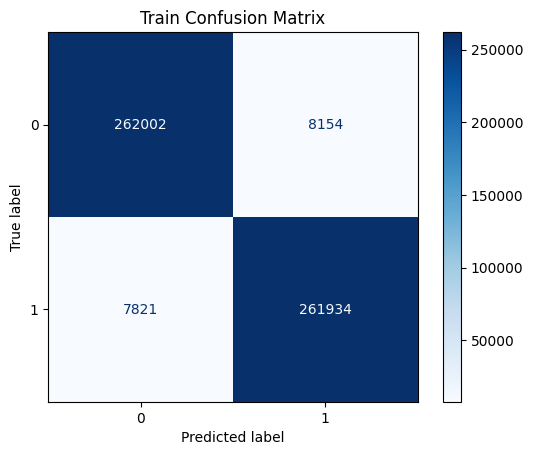

--- Test Metrics ---
AUC: 0.9917, Accuracy: 0.9621, Precision: 0.9620, F1-score: 0.9623


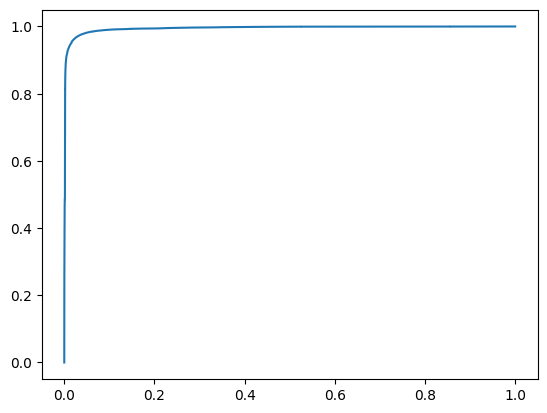

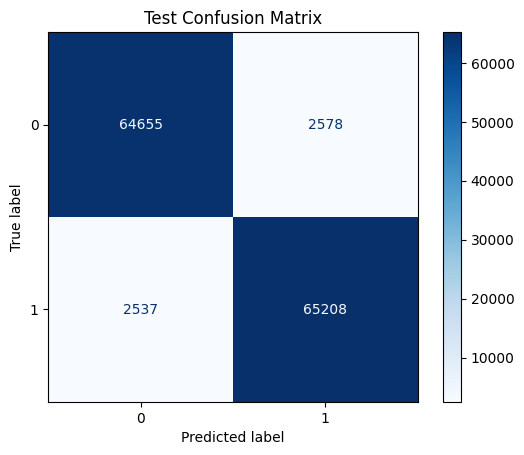

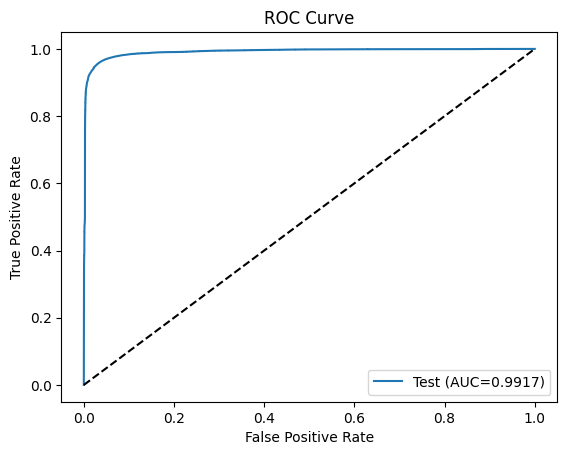

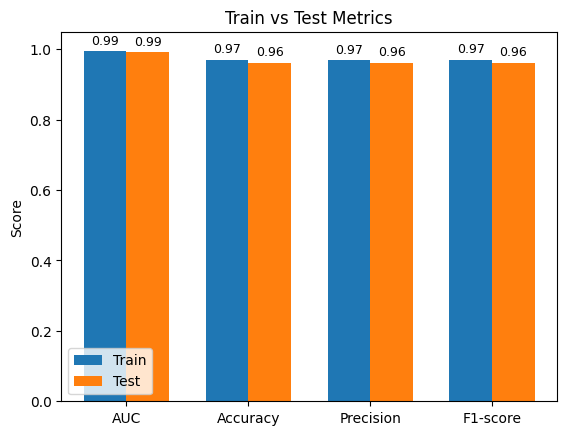

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

# Step 1: Evaluate model on train and test data
def evaluate_and_visualize(model, X_train, y_train, X_test, y_test):
    metrics = {}
    
    for dataset_name, X, y in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
        # Predict probabilities and labels
        y_probs = model.predict_proba(X)[:,1]
        y_pred = (y_probs > 0.5).astype(int)
        
        # Calculate metrics
        auc = roc_auc_score(y, y_probs)
        acc = accuracy_score(y, y_pred)
        precision = precision_score(y, y_pred)
        f1 = f1_score(y, y_pred)
        
        metrics[dataset_name] = {'AUC': auc, 'Accuracy': acc, 'Precision': precision, 'F1-score': f1}
        
        print(f"--- {dataset_name} Metrics ---")
        print(f"AUC: {auc:.4f}, Accuracy: {acc:.4f}, Precision: {precision:.4f}, F1-score: {f1:.4f}")
        
        # Confusion matrix
        cm = confusion_matrix(y, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(cmap=plt.cm.Blues)
        plt.title(f'{dataset_name} Confusion Matrix')
        plt.show()
        
        # ROC curve
        fpr, tpr, _ = roc_curve(y, y_probs)
        plt.plot(fpr, tpr, label=f'{dataset_name} (AUC={auc:.4f})')
    
    # Final ROC plot
    plt.plot([0,1], [0,1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend()
    plt.show()
    
    # Bar chart for metrics
    import numpy as np
    labels = list(metrics['Train'].keys())
    train_vals = [metrics['Train'][m] for m in labels]
    test_vals = [metrics['Test'][m] for m in labels]
    
    x = np.arange(len(labels))
    width = 0.35
    
    fig, ax = plt.subplots()
    rects1 = ax.bar(x - width/2, train_vals, width, label='Train')
    rects2 = ax.bar(x + width/2, test_vals, width, label='Test')
    
    ax.set_ylabel('Score')
    ax.set_title('Train vs Test Metrics')
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0,1.05)
    ax.legend()
    
    for i, v in enumerate(train_vals):
        ax.text(i - width/2, v + 0.02, f"{v:.2f}", ha='center', fontsize=9)
    for i, v in enumerate(test_vals):
        ax.text(i + width/2, v + 0.02, f"{v:.2f}", ha='center', fontsize=9)
    
    plt.show()
    
    return metrics

# Usage with your ensemble model
metrics = evaluate_and_visualize(ensemble_model, X_train, y_train, X_test, y_test)



--- Fold 1 ---
AUC: 0.9940, Accuracy: 0.9685, Precision: 0.9677, F1-score: 0.9685


<Figure size 800x600 with 0 Axes>

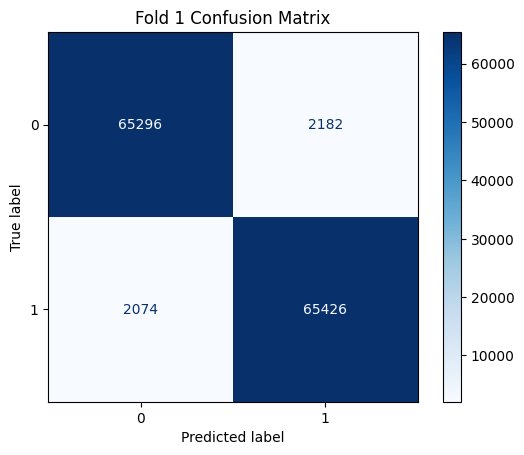

--- Fold 2 ---
AUC: 0.9941, Accuracy: 0.9688, Precision: 0.9684, F1-score: 0.9688


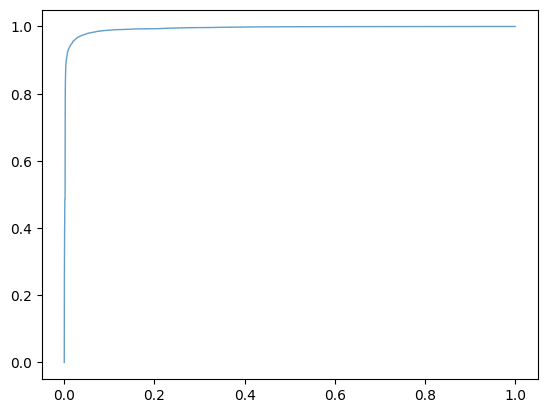

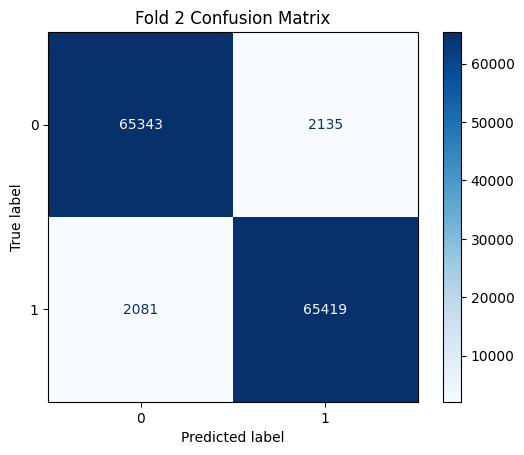

--- Fold 3 ---
AUC: 0.9942, Accuracy: 0.9688, Precision: 0.9679, F1-score: 0.9689


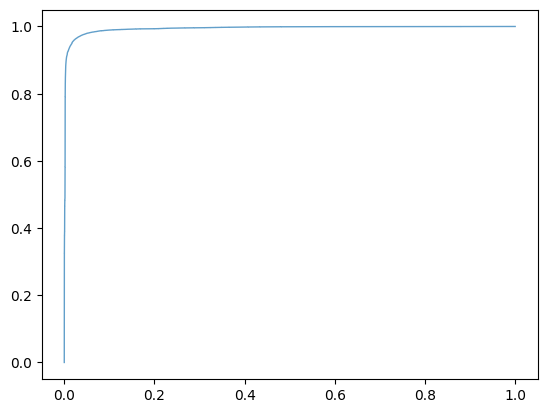

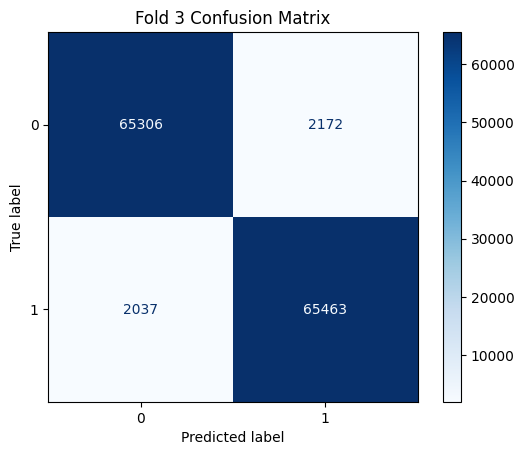

--- Fold 4 ---
AUC: 0.9939, Accuracy: 0.9687, Precision: 0.9685, F1-score: 0.9687


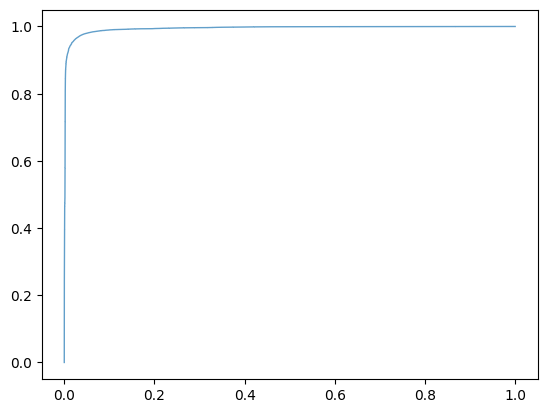

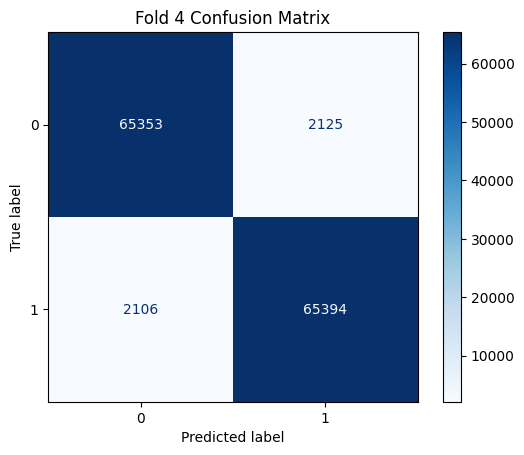

--- Fold 5 ---
AUC: 0.9943, Accuracy: 0.9691, Precision: 0.9687, F1-score: 0.9691


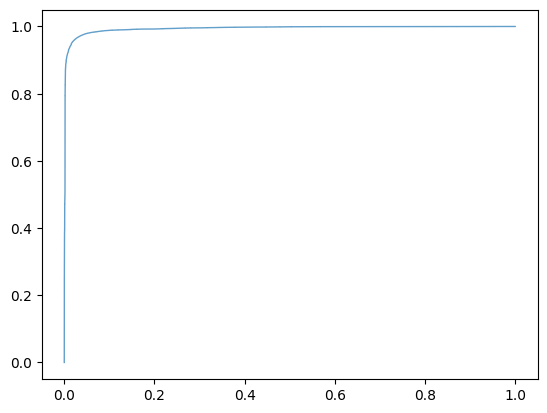

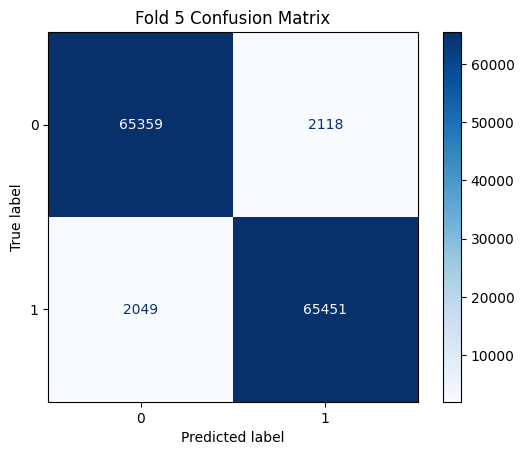

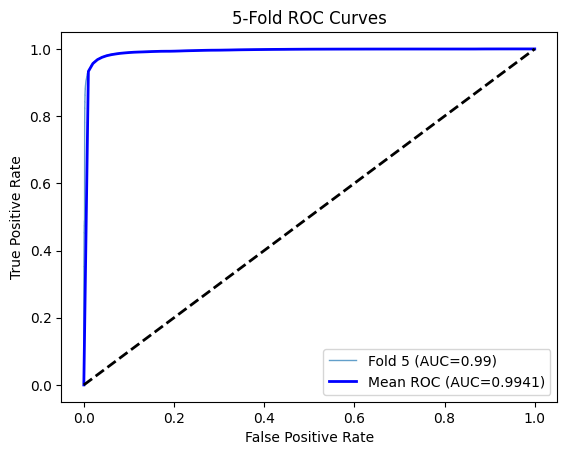

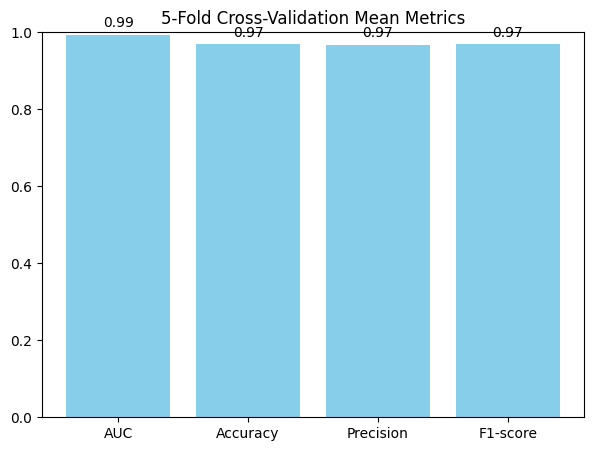

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

def kfold_evaluation_visualization(X, y, k=5):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=0)
    
    fold_metrics = {'AUC': [], 'Accuracy': [], 'Precision': [], 'F1-score': []}
    tprs = []  # For ROC curves
    mean_fpr = np.linspace(0,1,100)
    
    fold_idx = 1
    plt.figure(figsize=(8,6))
    
    for train_index, test_index in skf.split(X, y):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]
        
        # Train model
        model = LogisticRegression(max_iter=500, n_jobs=-1, random_state=0)
        model.fit(X_train, y_train)
        
        # Predict
        y_probs = model.predict_proba(X_test)[:,1]
        y_pred = (y_probs > 0.5).astype(int)
        
        # Metrics
        auc = roc_auc_score(y_test, y_probs)
        acc = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        
        fold_metrics['AUC'].append(auc)
        fold_metrics['Accuracy'].append(acc)
        fold_metrics['Precision'].append(precision)
        fold_metrics['F1-score'].append(f1)
        
        print(f"--- Fold {fold_idx} ---")
        print(f"AUC: {auc:.4f}, Accuracy: {acc:.4f}, Precision: {precision:.4f}, F1-score: {f1:.4f}")
        
        # Confusion matrix
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(cmap=plt.cm.Blues)
        plt.title(f'Fold {fold_idx} Confusion Matrix')
        plt.show()
        
        # ROC curve interpolation for mean
        fpr, tpr, _ = roc_curve(y_test, y_probs)
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        tprs[-1][0] = 0.0
        plt.plot(fpr, tpr, lw=1, alpha=0.7, label=f'Fold {fold_idx} (AUC={auc:.2f})')
        
        fold_idx += 1
    
    # Plot mean ROC curve
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = np.mean(fold_metrics['AUC'])
    plt.plot(mean_fpr, mean_tpr, color='b', lw=2, label=f'Mean ROC (AUC={mean_auc:.4f})')
    plt.plot([0,1],[0,1],'k--', lw=2)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{k}-Fold ROC Curves')
    plt.legend(loc='lower right')
    plt.show()
    
    # Bar chart of metrics
    metrics_names = list(fold_metrics.keys())
    metrics_values = [np.mean(fold_metrics[m]) for m in metrics_names]
    
    plt.figure(figsize=(7,5))
    plt.bar(metrics_names, metrics_values, color='skyblue')
    plt.ylim(0,1)
    for i, v in enumerate(metrics_values):
        plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontsize=10)
    plt.title(f'{k}-Fold Cross-Validation Mean Metrics')
    plt.show()
    
    return fold_metrics

# Usage
fold_metrics = kfold_evaluation_visualization(X, y, k=5)


0.9622975596023056

0.991752481848921

array([[64659,  2574],
       [ 2515, 65230]], dtype=int64)

c:\Users\SİNAN\AppData\Local\Programs\Python\Python310\python.exe


result_hybrid uzunluğu: 5


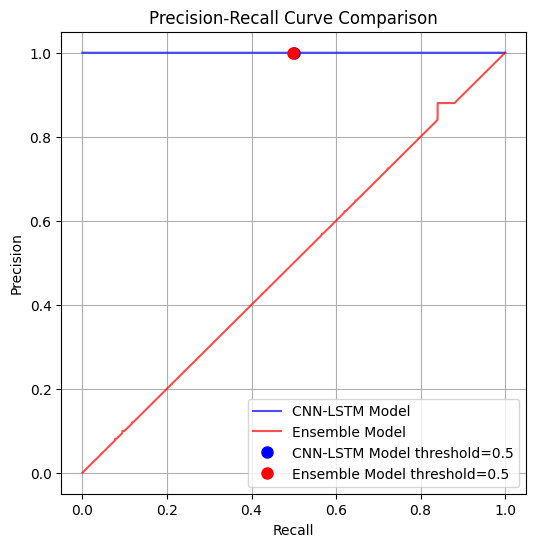

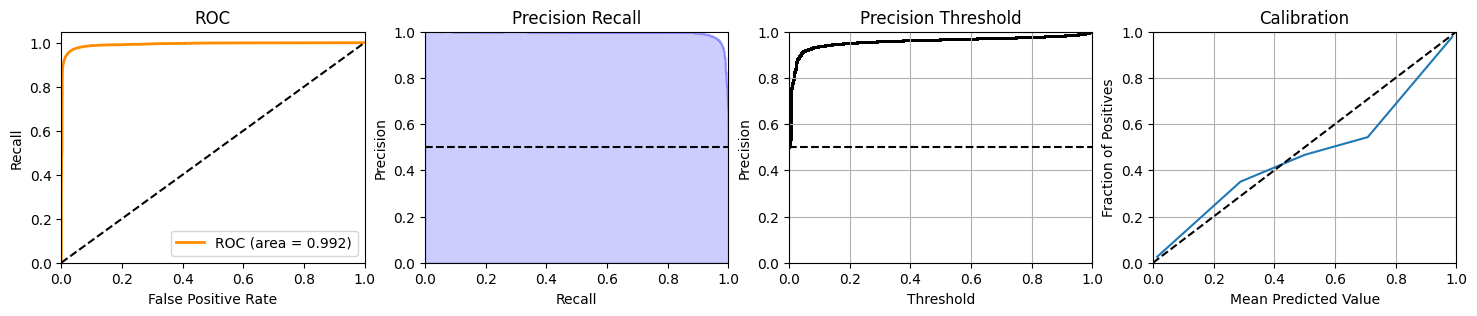